![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | Framing and Baseline

*Project 3 — AI Product: From Model to Product*

**Team:** Zoé Doucet

**Track:** LLM

**Data:** Forest Entomology and Pathology

---

Frame the product, look at the data, fix your evaluation before you build anything, and score the baseline your solution will have to beat.

> **Done when:** your framing is written down, you know what one row or one document is and what is wrong with the data, your test set or evaluation set is fixed, and you can say your metric and your baseline score out loud.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

---
## 1. Frame the product

Before any code. In a few sentences:

- **The user:** The typical user is someone who has a connection to nature but is not an expert in forestry. This could range from a curious garden owner to someone who owns a small plot of forest.

- **The input and output:** The final product will be a chatbot. Users will be able to ask questions or describe symptoms observed on a tree, such as signs of disease like insect infestations. The chatbot will respond with possible explanations based on the available scientific information or ask clarifying questions when more details are needed.

- **The decision:** The chatbot will help users better understand the possible causes of their tree's symptoms and decide whether they should seek further information or professional assistance.

- **The metric:** The chatbot will be evaluated using a set of predefined questions and symptom descriptions. The retrieval system will be assessed by measuring how often it identifies relevant passages from the reference book. The generated answers will be evaluated for factual accuracy, relevance, and whether they are supported by the retrieved information. The chatbot will be restricted to answering questions about tree health using only information from the reference book. It will not access external sources. The most costly mistake would be providing an incorrect or misleading answer, as this could cause users to misidentify a tree pest or take inappropriate action. An answer without supporting evidence is also problematic because users cannot verify the information. A refusal to answer is less harmful when the available evidence is insufficient. Therefore, the chatbot will be instructed to answer only when the textbook provides relevant information, clearly communicate uncertainty, and acknowledge when it cannot provide a reliable answer.I f the user provides insufficient information or the book does not contain the necessary evidence, the chatbot must acknowledge this rather than provide an unsupported answer.

You wrote a first version on launch day. Refine it here.

---
## 2. Load the data

Run `python download_data.py` (or `python download_data.py clothing`) from the repo root first. Your files land in `data/raw/`, which is gitignored.

In [2]:
reader = PdfReader("../data/raw/Forest_Entomology_and_Pathology.pdf")
print(len(reader.pages), "pages")

810 pages


---
## 3. First look

Shape, columns, a handful of rows **read in full**. What is one row? For the Amazon data, join a few reviews to their product in the metadata file on `parent_asin`.

In [3]:
# extracting text from one page
page = reader.pages[10]

text = page.extract_text()

print(text[:1500])

Contributors xi
Hervé´ Jactel´INRAE,´ University´ of´ Bordeaux,´ BIOGECO,´ Cestas,´ Bordeaux,´
France´
Paal´ Krokene´Division´ of´ Biotechnology´ and´ Plant´ Health,´ Norwegian´ Institute´ of´
Bioeconomy´ Research,´ Ås,´ Norway´
Stig´ Larsson´Swedish´ University´ of´ Agricultural´ Sciences,´ Uppsala,´ Sweden´
Andrew´ M.´ Liebhold´US´ Forest´ Service´ Northern´ Research´ Station,´ Morgantown,´
WV,´ USA´
Maria´ J.´ Lombardero´Unidade´ de´ Xestion´ Ambiental´ E´ Forestal´ Sostible,´ Univer-
sidade´ de´ Santiago´ de´ Compostela,´ Lugo,´ Spain´
Alex´ C.´ Mangini´Southern´ Region,´ Forest´ Health´ Protection,´ USDA´ Forest´ Service,´
Pineville,´ LA,´ USA´
Deborah´ G.´ McCullough´Department´ of´ Entomology´ and´ Department´ of´ Forestry,´
Michigan´ State´ University,´ East´ Lansing,´ MI,´ USA´
Zvi´ Mendel´Department´ of´ Entomology,´ Agriculture´ Research´ Organization,´ The´
V olcani´ Center,´ Bet´ Dagan,´ Israel´
Daniel´ R.´ Miller´USDA´ Forest´ Service,´ Southern´ Research´ Station,´ Athen

In [4]:
# extracting text from a few pages
for page_number in [0, 10, 50, 100]:
    text = reader.pages[page_number].extract_text() or ""

    print(f"\n--- PDF page {page_number + 1} ---")
    print(text[:500])


--- PDF page 1 ---


--- PDF page 11 ---
Contributors xi
Hervé´ Jactel´INRAE,´ University´ of´ Bordeaux,´ BIOGECO,´ Cestas,´ Bordeaux,´
France´
Paal´ Krokene´Division´ of´ Biotechnology´ and´ Plant´ Health,´ Norwegian´ Institute´ of´
Bioeconomy´ Research,´ Ås,´ Norway´
Stig´ Larsson´Swedish´ University´ of´ Agricultural´ Sciences,´ Uppsala,´ Sweden´
Andrew´ M.´ Liebhold´US´ Forest´ Service´ Northern´ Research´ Station,´ Morgantown,´
WV,´ USA´
Maria´ J.´ Lombardero´Unidade´ de´ Xestion´ Ambiental´ E´ Forestal´ Sostible,´ Univer-
sidade´

--- PDF page 51 ---
40 D. Doucet and T. D. Paine
Carlson´ RW´ (1983)´ Instar,´ stadium,´ and´ stage:´ deﬁnitions´ to´ ﬁt´ usage.´ Ann´ Entomol´ Soc´ Am´
76(3):319–319´
Casari´ SA,´ Teixeira´ ÉP´ (2014)´ Immatures´ of´ Acanthocinini´ (Coleoptera,´ Cerambycidae,´ Lamiinae).´
Rev´ Bras´ Entomol´ 58(2):107–128´
Cavaletto´ G,´ Faccoli´ M,´ Marini´ L,´ Spaethe´ J,´ Giannone´ F,´ Moino´ S,´ Rassati´ D´ (2020)´ Exploiting´
trap´ color´ to´ improve´ surveys´ of

The first inspection shows that text extraction is possible, but some formatting issues occur, including unwanted backticks, accents, line breaks, and words split across lines. The PDF also contains introductory material, such as contributor lists, that may not be relevant for retrieval. before building the RAG pages taht can be excluded should be identified.

In [5]:
pages = []

for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""

    pages.append({
        "pdf_page": i + 1,
        "text": text})

df = pd.DataFrame(pages)

df.head()

,pdf_page,text
0,1,
1,2,Forest´ Entomology´ and´ Pathology
2,3,Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· \nBernard´ Slippers´· Michael´ J.´ Wingﬁeld´\nEditors´\nForest´ Entomology´\nand´ Pathology´\nV olume´ 1:´ Entomology
3,4,"Editors \nJeremy´ D.´ Allison´\nNatural´ Resources´ Canada´\nSault´ Ste.´ Marie,´ ON,´ Canada´\nBernard´ Slippers´\nForestry´ and´ Agricultural´ Biotechnology´\nInstitute´\nUniversity´ of´ Pretori..."
4,5,"Preface´\nThe´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´\nduring´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ ..."


---
## 4. Data quality

Empty and very short texts, HTML (`<br />`, `&#34;`), duplicates, texts in other languages, missing titles or metadata. Write down what you find and what you will do about it. Put the cleaning in a function in `src/functions.py`: the app will need it too.

### 4.1 Text length and content

In [6]:
# number of empty pages
empty = (df["text"].str.strip() == "").sum()
print(empty)

1


In [7]:
# numbr of duplicate pages
duplicates = df["text"].duplicated().sum()
print(duplicates)

0


In [8]:
# length of text on each page
text_length = df["text"].str.len()
round(text_length.describe(), 2)

count     810.00
mean     3118.09
std      1056.02
min         0.00
25%      2383.00
50%      3357.50
75%      3903.25
max      4913.00
Name: text, dtype: float64

In [9]:
# checking for very short pages
df["text_length"] = df["text"].str.len()

short_pages = df[df["text_length"] < 200]

print("Pages with fewer than 200 characters:", len(short_pages))

display(short_pages[["pdf_page", "text_length"]].head(20))

Pages with fewer than 200 characters: 3


,pdf_page,text_length
0,1,0
1,2,34
2,3,155


In [10]:
# checking the content of short pages
for pdf_page in [1, 2, 3]:
    print(f"\n--- PDF page {pdf_page} ---")
    print(df.loc[pdf_page - 1, "text"])


--- PDF page 1 ---


--- PDF page 2 ---
Forest´ Entomology´ and´ Pathology

--- PDF page 3 ---
Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· 
Bernard´ Slippers´· Michael´ J.´ Wingﬁeld´
Editors´
Forest´ Entomology´
and´ Pathology´
V olume´ 1:´ Entomology


In [11]:
# checking the content of first and last pages
for i in list(range(5)) + list(range(len(df) - 5, len(df))):
    print(f"\n--- PDF page {i + 1} ---")
    print(df.loc[i, "text"][:250])


--- PDF page 1 ---


--- PDF page 2 ---
Forest´ Entomology´ and´ Pathology

--- PDF page 3 ---
Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· 
Bernard´ Slippers´· Michael´ J.´ Wingﬁeld´
Editors´
Forest´ Entomology´
and´ Pathology´
V olume´ 1:´ Entomology

--- PDF page 4 ---
Editors 
Jeremy´ D.´ Allison´
Natural´ Resources´ Canada´
Sault´ Ste.´ Marie,´ ON,´ Canada´
Bernard´ Slippers´
Forestry´ and´ Agricultural´ Biotechnology´
Institute´
University´ of´ Pretoria´
Hatﬁeld,´ South´ Africa´
Timothy´ D.´ Paine´
Department´ o

--- PDF page 5 ---
Preface´
The´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´
during´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ and´ the´
ecology´ of´ invasive´ forest´ insects.´ In´ t

--- PDF page 806 ---
806 A. M. Liebhold et al.
Boyd IL, Freer-Smith PH, Gilligan CA, Godfray HCJ (2013) The consequence of tree pests and 
diseases for ecosystem services. Science 342:1235773 
Brockerhoff 

In [12]:
# makinf sure all text is in english
for page_number in [50, 150, 300, 450, 700]:
    text = df.loc[page_number, "text"]

    print(f"\n--- PDF page {page_number + 1} ---")
    print(text[:300])


--- PDF page 51 ---
40 D. Doucet and T. D. Paine
Carlson´ RW´ (1983)´ Instar,´ stadium,´ and´ stage:´ deﬁnitions´ to´ ﬁt´ usage.´ Ann´ Entomol´ Soc´ Am´
76(3):319–319´
Casari´ SA,´ Teixeira´ ÉP´ (2014)´ Immatures´ of´ Acanthocinini´ (Coleoptera,´ Cerambycidae,´ Lamiinae).´
Rev´ Bras´ Entomol´ 58(2):107–128´
Cavaletto´ 

--- PDF page 151 ---
142 J.-C. Grégoire and J. R. Gould
6.2´ Natural´ Enemies´
Any organism feeding on another species or group of species during at least one 
developmental stage can be described as a “natural enemy”, a category to which 
predators, parasitoids and pathogens attacking forest insects obviously belong. T

--- PDF page 301 ---
9 Foliage Feeders 293
Sharov´ AA,´ Roberts´ EA,´ Liebhold´ AM´ et´ al´ (1995)´ Gypsy´ moth´ (Lepidoptera:´ Lymantriidae)´ spread´
in´ the´ central´ Appalachians:´ three´ methods´ for´ species´ boundary´ estimation.´ Environ´ Entomol´
24(6):1529–1538.´https://doi.org/10.1093/ee/24.6.1529´
Sharov´ AA,

--- PDF page 451 ---
446 M. Bra

The book only has one empty page
The book has zero duplicate pages
page legth is okay
only three pages with fewer than 200 characters: pages 1,2 and 3.


### 4.2 special characters

In [13]:
# counting the number of pages containing backticks and accents
df["backtick_count"] = df["text"].str.count("`")
df["acute_count"] = df["text"].str.count("´")

print("Pages containing backticks:", (df["backtick_count"] > 0).sum())
print("Pages containing acute accents:", (df["acute_count"] > 0).sum())

Pages containing backticks: 60
Pages containing acute accents: 427


In [14]:
# checking for httml and other artifacts
html_pattern = r"<(?:div|p|span|br|html|body)\b[^>]*>"

html_pages = df[
    df["text"].str.contains(
        html_pattern,
        case=False,
        regex=True,
        na=False)]

print("Pages with HTML-like tags:", len(html_pages))

Pages with HTML-like tags: 0


In [ ]:
# checking for line break hyphenation
hyphenated_pages = df[
    df["text"].str.contains(r"\w-\s*\n\s*\w", regex=True, na=False)]

print("Pages with line break hyphenation:", len(hyphenated_pages))

Pages with line-break hyphenation: 626


#### 4.4 Page number match

In [16]:
# checking page number matches
print("Missing page numbers:", df["pdf_page"].isna().sum())
print("Missing text values:", df["text"].isna().sum())
print("Unique page numbers:", df["pdf_page"].nunique())

Missing page numbers: 0
Missing text values: 0
Unique page numbers: 810


In [17]:
# checking for page offset
for pdf_page in [30, 50, 101, 150, 300, 500, 700]:
    text = df.loc[pdf_page - 1, "text"]

    print(f"\nPDF page {pdf_page}")
    print("Beginning:", repr(text[:120]))
    print("End:", repr(text[-120:]))


PDF page 30
Beginning: 'Chapter 2 \nForm and Function \nDaniel Doucet and Timothy D. Paine \nInsect´ form´ and´ function´ is´ a´ vast´ ﬁeld´ of´ kn'
End: '23´\nJ.´ D.´ Allison´ et´ al.´ (eds.),´F orest Entomology and Pathology,´\nhttps://doi.org/10.1007/978-3-031-11553-0_2´\n19'

PDF page 50
Beginning: '2 Form and Function 39\nchromosomes),´ known´ as´ haplo-diploid´ sex´ determination.´ As´ a´ consequence,´ in´\nmany´ spec'
End: 'ects:´ a´ review´ and´ synthesis´ of´ size-and´\nbrain-dependent´ and´ independent´ mechanisms.´ Biol´ Rev´ 88(4):944–954'

PDF page 101
Beginning: 'Chapter 4 \nInsect Ecology \nLaurel J. Haavik and Fred M. Stephen \n4.1 Introduction \nInsect` ecology` is` the` study` of` '
End: '23`\nJ.` D.` Allison` et` al.` (eds.),`F orest Entomology and Pathology,`\nhttps://doi.org/10.1007/978-3-031-11553-0_4`\n91'

PDF page 150
Beginning: 'Chapter´ 6´\nForest´ Insect–Natural´ Enemy´\nInteractions´\nJean-Claude´ Grégoire´ and´ Juli´ R.´ Gould´\n6.1´ Introduction´'
End: '

### Data quality inspection findings

The dataset consists of an 810-page scientific textbook extracted using `pypdf`. Each row represents one PDF page and contains the extracted text and a unique PDF page number.

The initial quality checks found one empty page (PDF page 1) and no duplicate pages. PDF pages 2 and 3 contain introductory title and editor information rather than scientific content and can be therefore excluded from searchable content.

The extraction contains several formatting artifacts. Backticks occur on 60 pages, acute-accent characters (`´`) occur on 427 pages, and line-break hyphenation occurs on 626 pages. Other observed issues include unusual circumflex-like characters, split words, and ligatures.

The scientific text appears to be predominantly English. No HTML tags were detected, although DOI and HTTP links appear in the text.

The printed textbook page numbers differ from PDF page numbers, and the offset is not constant. Therefore, PDF page numbers will be preserved as reliable source identifiers for the initial RAG system.

The book contains reference lists at the end of individual chapters, rather than one bibliography at the end. These sections may be less useful for answering user questions and should be considered during document preparation.

**Planned preprocessing:** Normalize confirmed extraction artifacts, repair line-break hyphenation, and normalize whitespace. The original extracted text will be preserved for comparison. Empty pages and irrelevant front matter will be excluded from retrieval, while chapter-level reference sections will be assessed before filtering.

#### 4.5 Cleaning the data

In [18]:
# testing the cleaning function on a sample
sample = "Insect` ecology` is` the` study` of` the` environ-\nment."

print("Before:", sample)
print("After: ", clean_text(sample))

Before: Insect` ecology` is` the` study` of` the` environ-
ment.
After:  Insect ecology is the study of the environment.


The cleaning works well on the sample.

In [19]:
# cleaning the text
df["clean_text"] = df["text"].apply(clean_text)

df[["pdf_page", "text", "clean_text"]].head()

,pdf_page,text,clean_text
0,1,,
1,2,Forest´ Entomology´ and´ Pathology,Forest Entomology and Pathology
2,3,Jeremy´ D.´ Allison´· Timothy´ D.´ Paine´· \nBernard´ Slippers´· Michael´ J.´ Wingﬁeld´\nEditors´\nForest´ Entomology´\nand´ Pathology´\nV olume´ 1:´ Entomology,Jeremy D. Allison · Timothy D. Paine · Bernard Slippers · Michael J. Wingfield Editors Forest Entomology and Pathology V olume 1: Entomology
3,4,"Editors \nJeremy´ D.´ Allison´\nNatural´ Resources´ Canada´\nSault´ Ste.´ Marie,´ ON,´ Canada´\nBernard´ Slippers´\nForestry´ and´ Agricultural´ Biotechnology´\nInstitute´\nUniversity´ of´ Pretori...","Editors Jeremy D. Allison Natural Resources Canada Sault Ste. Marie, ON, Canada Bernard Slippers Forestry and Agricultural Biotechnology Institute University of Pretoria Hatfield, South Africa Tim..."
4,5,"Preface´\nThe´ idea´ for´ this´ book´ emerged´ from´ conversations´ between´ the´ editors,´ in´ particular´\nduring´ visits´ by´ JDA´ to´ South´ Africa´ to´ work´ with´ BS´ on´ plantation´ pests´ ...","Preface The idea for this book emerged from conversations between the editors, in particular during visits by JDA to South Africa to work with BS on plantation pests and the ecology of invasive fo..."


The cleaning seems to work on the text as well. However let's check a few pages.

In [21]:
# checking a few pages
for pdf_page in [101, 150, 500]:
    row = df[df["pdf_page"] == pdf_page].iloc[0]

    print(f"\n--- PDF page {pdf_page} ---")
    print(row["clean_text"][:700])


--- PDF page 101 ---
Chapter 4 Insect Ecology Laurel J. Haavik and Fred M. Stephen 4.1 Introduction Insect ecology is the study of how insects interact with the environment. The environment consists of both physical characteristics (abiotic) and other organisms (biotic). Insects are natural components of forests and perform a variety of essential functions that help maintain forests as ecosystems. As consumers of forest products, people sometimes compete with insects for forest resources. Most research and management efforts in forest entomology have focused on insects that damage or kill large numbers of ecologically or economically important trees. In this chapter, we consider the various environmental challen

--- PDF page 150 ---
Chapter 6 Forest Insect–Natural Enemy Interactions Jean-Claude Grégoire and Juli R. Gould 6.1 Introduction As illustrated in several other chapters of this book, “forest insects”, including those linked to woody plants growing outside the forest environme

In [22]:
# checking for remaining artifacts
for char in ["`", "´", "ˆ", "\u0301", "\u0302"]:
    count = df["clean_text"].str.contains(
        char, regex=False).sum()

    print(f"{repr(char)}: {count} pages")

'`': 0 pages
'´': 0 pages
'ˆ': 0 pages
'́': 0 pages
'̂': 0 pages


### Cleaning validation

The cleaning function was tested on scientific text from PDF pages 101, 150, and 500. The cleaned passages were readable and preserved the scientific explanations and species names.

After cleaning, none of the 810 pages contained the five checked extraction artifacts: backticks, acute-accent marks, circumflex-like marks, or their combining-character equivalents.

Some minor formatting issues remain, including occasional spaces within words. These were left unchanged to avoid introducing errors through overly aggressive cleaning.

The cleaned text is considered suitable for the initial retrieval baseline. The original text remains available for comparison.

---
## 5. Look at the texts

Lengths, the most frequent words, how the texts differ between ratings, products or periods. Read some hard cases: the 3-star reviews, the sarcastic ones, the ones whose rating and text disagree.

In [23]:
# taking a look at the cleaned text length
df["clean_text_length"] = df["clean_text"].str.len()

df["clean_text_length"].describe()

count     810.000000
mean     2903.860494
std       969.020529
min         0.000000
25%      2221.000000
50%      3195.000000
75%      3625.500000
max      4300.000000
Name: clean_text_length, dtype: float64

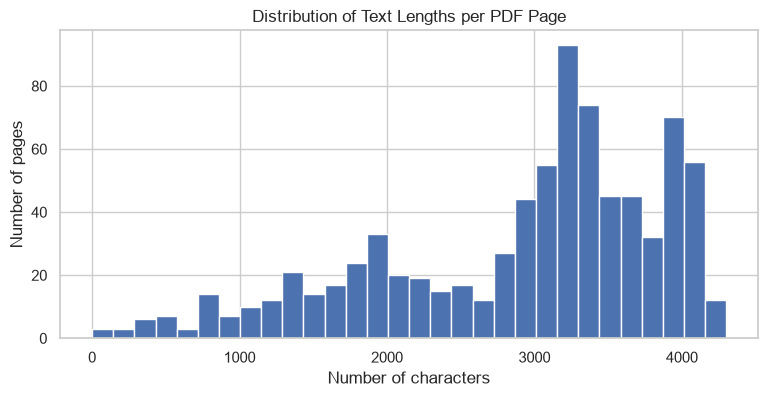

In [ ]:
plt.figure(figsize=(9, 4))

plt.hist(df["clean_text_length"], bins=30)

plt.title("Distribution of Text Lengths per PDF Page")
plt.xlabel("Number of characters")
plt.ylabel("Number of pages")

plt.show()

In [27]:
# taking a closer look at the longest and shortest pages
print("Shortest pages:")
display(df.nsmallest(5, "clean_text_length")[
        ["pdf_page", "clean_text_length", "clean_text"]])

print("Longest pages:")
display(df.nlargest(5, "clean_text_length")[
        ["pdf_page", "clean_text_length", "clean_text"]])

Shortest pages:


,pdf_page,clean_text_length,clean_text
0,1,0,
1,2,31,Forest Entomology and Pathology
2,3,140,Jeremy D. Allison · Timothy D. Paine · Bernard Slippers · Michael J. Wingfield Editors Forest Entomology and Pathology V olume 1: Entomology
606,607,236,"17 IPM: The Forest Context 605 Fig. 17.11 Insecticides used for management of spruce budworm, Choristoneura fumiferana,i n Canada (Figure credit: C.J.K. MacQuarrie, Natural Resources Canada; repro..."
685,686,255,684 E. G. Brockerhoff et al. Fig. 19.8 Advertising used for the “Catch it - call us” campaign by New Zealand’s national biosecurity agency MPI to encourage reporting finds of an invasive insect. S...


Longest pages:


,pdf_page,clean_text_length,clean_text
518,519,4300,"15 Tip, Shoot, Root, and Regeneration Pests 515 Coyle DR, Nebeker TE, Hart ER, Mattson WJ Jr (2005) Biology and management of insect pests in North American intensively-managed hardwood forest sys..."
286,287,4279,9 Foliage Feeders 279 Embree DG (1967) Effects of winter moth on growth and mortality of red oak in Nova Scotia. For Sci 13(3):295–299. https://academic.oup.com/forestscience/article-abstract/13/3...
570,571,4244,"568 W. B. Strong et al. Barbosa P , Hines J, Kaplan I, Martinson H, Szczepaniec A, Szendrei Z (2009) Associational resistance and associational susceptibility: having right or wrong neighbors. Ann..."
96,97,4234,"3 Forest Arthropod Diversity 87 Schabel H (2010) Forest insects as food: a global review. In: Durst PB, Johnson DV , Leslie RN, Shono K (eds) Forest insects as food: humans bite back. Proceedings ..."
291,292,4231,"284 J. Elkinton and A. Roehrig Kenis M, Hurley BP , Hajek AE et al (2017) Classical biological control of insect pests of trees: facts and figures. Biol Invasions 19:3401–3417. https://doi.org/10...."


cleaned text legth slightly shorter but not to much. distribution not normal one peak around 2000 and one peak arround 3000.

#### 5.2 Most frequent words

In [25]:
from sklearn.feature_extraction.text import CountVectorizer

In [26]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20)

word_matrix = vectorizer.fit_transform(df["clean_text"])

word_counts = word_matrix.sum(axis=0).A1

frequent_words = pd.DataFrame({"word": vectorizer.get_feature_names_out(), "count": word_counts}).sort_values("count", ascending=False)

display(frequent_words)

,word,count
1,al,3419
6,et,3400
17,species,2263
7,forest,2154
12,insects,1473
11,insect,1433
19,trees,1314
15,pine,1116
3,beetle,1086
18,tree,1072


### Text exploration findings

After cleaning, the dataset still contains 810 PDF pages, including one empty page. The average cleaned text length is approximately 2,904 characters per page, with a median of 3,195 characters and a maximum of 4,300 characters.

The cleaned text is slightly shorter than the original because extraction artifacts and unnecessary whitespace were removed.

The shortest pages are mainly introductory pages or pages near chapter endings. The longest pages contain dense text with no images.

The most frequent words include expected  terms such as *species*, *forest*, *insects*, *trees*, *pine*, *beetle*, and *host*. However, words such as *et*, *al*, *https*, *org*, and *entomol* also appear frequently, suggesting that bibliographic references contribute substantially to the text.

This may affect retrieval quality because a search could return bibliography entries instead of explanatory passages. During document preparation, I will investigate how to handle reference-heavy content while preserving useful scientific information.

Overall, the cleaned text appears suitable for building an initial retrieval system.

---
## 6. LLM track — the documents and the evaluation set

Skip this section on the model track.

- **Prepare the documents:** which texts the system will search (reviews, product descriptions, or both), how you chunk them, and the metadata each chunk keeps (product, rating, date, id), so that answers can cite them.
- **Write the evaluation set now, before you build:** at least 15 questions your user would really ask, each with the expected answer or the id of the source that answers it, and **at least 3 questions the data cannot answer**. Save it as a CSV in `data/` (it is small, and it is yours, so you can commit it).

---
## 7. The baseline

The simplest thing that could work, scored with the same evaluation as your final solution.

- **Model track:** a `DummyClassifier`, then TF-IDF with logistic regression, scored with cross-validation on the training set.
- **LLM track:** the LLM alone (no retrieval, no tools) on your evaluation set, or a keyword search (TF-IDF) for the retrieval part. Log the tokens and the cost.

---
## 8. What the baseline tells you

In prose: how good is the baseline, which mistakes does it make, and what do you expect your solution to fix?